In [ ]:
import numpy as np
import pandas as pd

from spec5.instrument.fiber import mock_fiber_assign

from matplotlib import pyplot as plt


In [2]:
def sample_plummer_2d(n_stars, rhalf, random_state=None):
    """
    Sample 2D projected positions from a Plummer distribution.
    
    Parameters
    ----------
    n_stars : int
        Number of stars to sample
    rhalf : float
        Half-light radius (same units as output x, y)
    random_state : int, optional
        Random seed for reproducibility
    
    Returns
    -------
    x, y : arrays
        2D positions in same units as rhalf
    """
    rng = np.random.default_rng(random_state)
    
    # Sample projected radius from Plummer CDF
    # P(R) = R^2 / (R^2 + a^2), inverting: R = a * sqrt(u) / sqrt(1 - u)
    u = rng.uniform(0, 0.9999, n_stars)  # avoid u=1 (infinite radius)
    R = rhalf * np.sqrt(u) / np.sqrt(1 - u)
    
    # Sample random angles
    theta = rng.uniform(0, 2*np.pi, n_stars)
    
    # Convert to Cartesian coordinates
    x = R * np.cos(theta)
    y = R * np.sin(theta)
    
    return x, y


In [12]:
# SpecS5 FoV
FoV = 1.1  # degrees (diameter)
# SpecS5 fiber count
n_fibers = 13000

# Sample Plummer Distribution
x, y = sample_plummer_2d(
    n_stars=int(1e6), 
    rhalf=0.2  # arcmin
)
# Sample magnitudes uniformly between 15 and 22
zmag = np.random.uniform(15, 22, len(x))

# Create "catalog" DataFrame
catalog = pd.DataFrame({
    "x": x,
    "y": y,
    "zmag": zmag
})

catalog_observed = mock_fiber_assign(
    catalog=catalog,
    n_fibers=n_fibers,
    fov_radius_arcmin=FoV / 2 * 60,
    n_passes=1,
    n_grid_cells=65,
    priority_column="zmag",
    priority_order_ascending=True,
    random_seed=None,
)

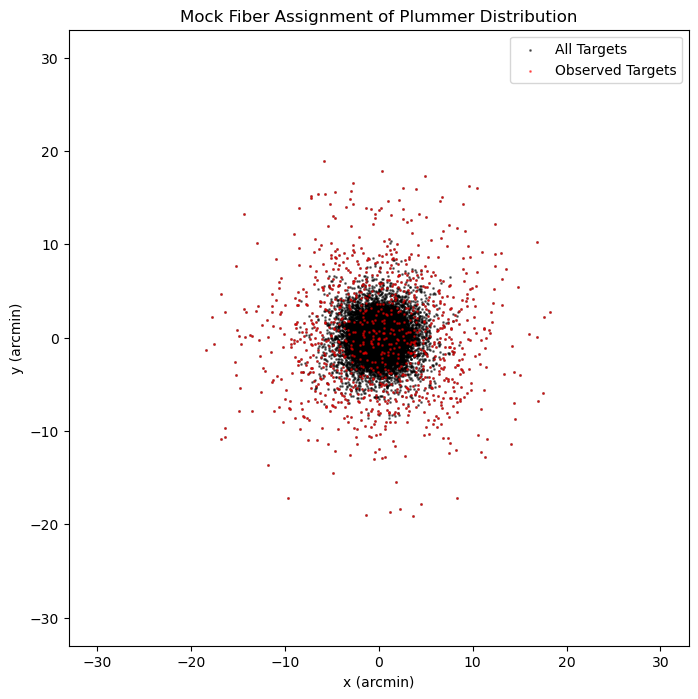

In [13]:
plt.figure(figsize=(8, 8))

plt.scatter(
    catalog['x'], 
    catalog['y'], 
    s=1, 
    c='k',
    alpha=0.5, 
    label='All Targets'
)
plt.scatter(
    catalog_observed['x'], 
    catalog_observed['y'], 
    s=1, 
    c='r',
    alpha=0.5, 
    label='Observed Targets'
)

plt.xlabel('x (arcmin)')
plt.ylabel('y (arcmin)')
plt.title('Mock Fiber Assignment of Plummer Distribution')
plt.legend()
plt.xlim(-FoV/2*60, FoV/2*60)
plt.ylim(-FoV/2*60, FoV/2*60)
plt.show()